# Club convergence in Python: a tutorial

This notebook walks through a complete club convergence analysis with `convergence_clubs`:

1. prepare the data;
2. test whether the whole panel converges;
3. find convergence clubs and merge them;
4. check how robust the clubs are;
5. complement them with β-convergence, σ-convergence and distribution dynamics;
6. replicate a published Stata analysis;
7. export everything as a report.

It uses the GDP data of Phillips and Sul (2009), which ships with the package, and the productivity data of Mendez (2020). The test suite runs every cell, so the code always works with the installed version.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import convergence_clubs as cc

pd.set_option("display.precision", 3)

## 1. Prepare the data

The data are a pandas DataFrame with **units in rows** (the index holds the names) and **periods in columns**. Phillips and Sul work with the log of income per capita, smoothed with a Hodrick-Prescott filter to remove business cycles. They use λ = 400 for annual data.

In [2]:
gdp = cc.load_gdp()  # levels: 152 countries x 1970-2003
trend = cc.hp_filter(np.log(gdp), lamb=400)
gdp.iloc[:5, :6]

year,1970,1971,1972,1973,1974,1975
Countries,,,,,,
Afghanistan,1731.110,1748.382,2119.625,2119.436,2148.020,2263.112
Algeria,4280.134,3830.378,4621.212,4425.815,4043.566,3987.897
Antigua,5167.933,4978.538,5249.234,5021.922,5169.575,4871.257
Argentina,9739.775,9947.783,9945.670,10179.488,10591.224,10363.500
Australia,14672.852,15080.587,15364.975,15898.595,15617.894,15834.019


If your data are in long format (one row per unit and year), `cc.wide_panel(df, unit=..., time=..., value=...)` reshapes them. `cc.describe_missing`, `cc.fill_gaps` and `cc.balance` help with gaps.

## 2. Does the whole panel converge?

The **log t test** regresses log(H₁/Hₜ) − 2 log(log t) on log t, where Hₜ is the cross-sectional variation, after dropping the first third of the periods. The null hypothesis is convergence, and it is **rejected when t < −1.65**.

In [3]:
H = cc.cross_sectional_variation(trend.to_numpy())
cc.log_t_test(H, time_trim=1 / 3)

LogTResult(beta=-0.8748112403765451, std_err=0.005482815507487353, t_value=-159.5551116359651, p_value=0.0, alpha=0.3982137415021766)

t = −159.6 is far below −1.65, so the 152 countries do not converge to a common path. The question is whether there are **groups** that do.

## 3. Convergence clubs

`find_clubs` sorts the units by their last value. It then forms a core group, adds to the core every unit that converges with it (t above c* = 0), and repeats the procedure on the units that are left.

In [4]:
clubs = cc.find_clubs(trend)
clubs.summary()

,n_units,beta,std_err,t_value,p_value,converges,cstar
club,,,,,,,
club1,50,0.382,0.041,9.282,1.000,True,0.0
club2,30,0.240,0.035,6.904,1.000,True,0.0
club3,21,0.110,0.032,3.402,1.000,True,0.0
club4,24,0.131,0.064,2.055,0.980,True,0.0
club5,14,0.190,0.111,1.701,0.956,True,0.0
club6,11,1.003,0.166,6.024,1.000,True,0.0
club7,2,-0.470,0.842,-0.559,0.288,True,0.0


How to read the table:
- `t_value` is each club's own log t test, and every club should have t > −1.65 (`converges`). With the default `cstar_method="fixed"` a club can fail; `find_clubs` then warns, and Phillips and Sul suggest `cstar_method="incremental"`.
- `beta` measures the speed: β ≥ 2 means convergence in levels, while 0 ≤ β < 2 means the gaps shrink only in relative terms.

The procedure tends to over-split, so adjacent clubs that converge together are merged:

In [5]:
merged = clubs.merge("PS")
merged.summary(members=True)[["n_units", "t_value", "merged_clubs", "members"]]

,n_units,t_value,merged_clubs,members
club,,,,
club1,50,9.282,club1,United States; Norway; Bermuda; United Arab Em...
club2,30,6.904,club2,Bahrain; Bahamas; Barbados; Saudi Arabia; Trin...
club3,21,3.402,club3,Venezuela; Iran; Suriname; Algeria; Cuba; Roma...
club4,38,-0.636,"club4, club5",Jordan; Nicaragua; Samoa; Bolivia; Vanuatu; Zi...
club5,11,6.024,club6,Central African Republic; Zambia; Niger; Togo;...
club6,2,-0.559,club7,"Congo, Dem. Rep.; Liberia"


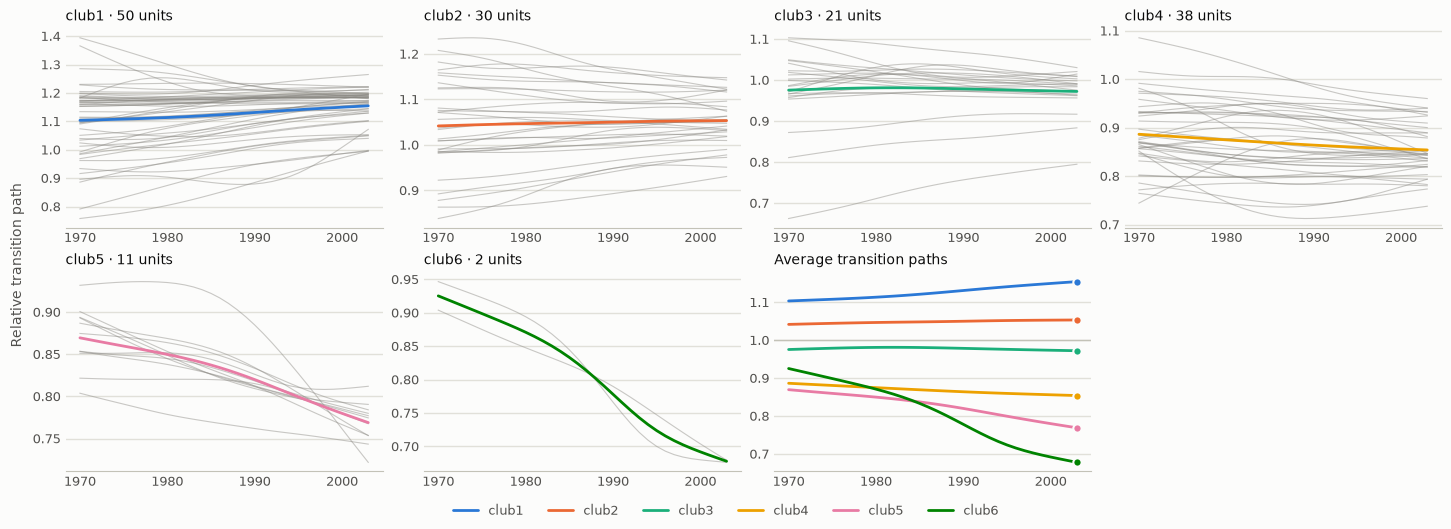

In [6]:
merged.plot(ncols=4);

Each panel shows the relative transition paths of a club's units: income relative to the cross-sectional mean, with the club average in color. The last panel compares the club averages. The clubs settle at different relative levels, which is what club convergence means.

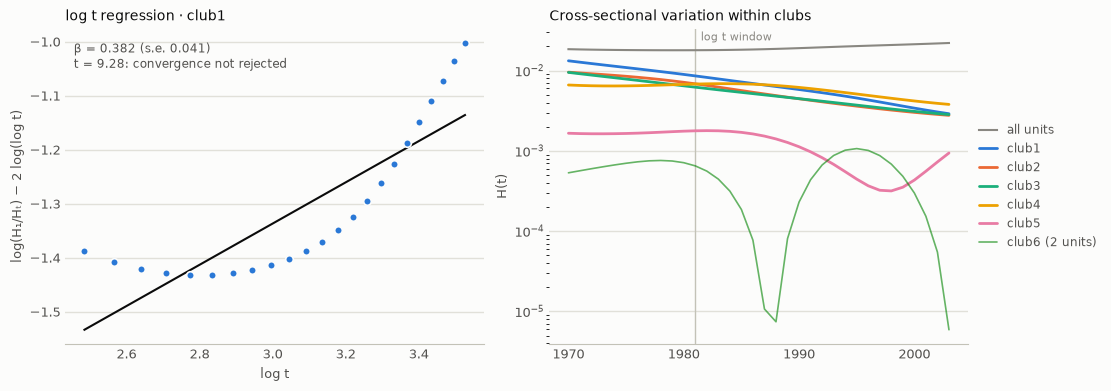

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
merged.plot.log_t("club1", ax=axes[0])
merged.plot.variation(ax=axes[1]);

Left: the log t regression of club 1, with a positive slope and t far above −1.65. Right: the cross-sectional variation H(t). Over the regression window it falls by 44–66% in the four largest clubs, while for the panel as a whole it rises by about 23%. Very small clubs (here two countries) give erratic H(t) paths, so read them with care.

## 4. How robust are the clubs?

Club memberships depend on choices such as the trimming fraction and the HAC estimator. `sensitivity` reruns the procedure over a grid of these settings. `ari_vs_baseline` is the adjusted Rand index of agreement with the first run: 1 means identical clubs, 0 means chance agreement.

In [8]:
runs = cc.sensitivity(trend, merge=["PS"])
runs.table()

,time_trim,hac_method,cstar,merge,sort_fraction,n_units,n_clubs,n_divergent,n_failing,sizes,ari_vs_baseline
0,0.333,FQSB,0.0,PS,0.0,152,6,0,0,50-30-21-38-11-2,1.000
1,0.333,AQSB,0.0,PS,0.0,152,4,3,1,84-18-40-7,0.586
2,0.250,FQSB,0.0,PS,0.0,152,6,0,0,54-45-19-21-11-2,0.658
3,0.250,AQSB,0.0,PS,0.0,152,5,0,1,95-23-21-11-2,0.379
4,0.300,FQSB,0.0,PS,0.0,152,6,0,0,55-43-25-22-5-2,0.663
5,0.300,AQSB,0.0,PS,0.0,152,5,1,1,79-20-22-25-5,0.554
6,0.400,FQSB,0.0,PS,0.0,152,6,0,0,57-39-32-13-9-2,0.661
7,0.400,AQSB,0.0,PS,0.0,152,4,2,0,71-38-28-13,0.568


`bootstrap` perturbs the data instead of the settings. Here it clusters 100 random subsamples of 80% of the countries. A unit's **stability** is the share of runs in which it stays with its full-sample club mates.

In [9]:
boot = cc.bootstrap(trend, 100, merge="PS", seed=0)
boot.uncertain(0.8).head(8)

,baseline_club,stability,divergent_share,n_runs
Countries,,,,
Jordan,club4,0.466,0.000,86
Vanuatu,club4,0.476,0.000,85
Somalia,club5,0.523,0.373,83
Rwanda,club5,0.543,0.111,81
"Gambia, The",club4,0.561,0.000,80
Cambodia,club4,0.568,0.000,77
Guinea,club4,0.584,0.000,77
Bhutan,club3,0.594,0.000,84


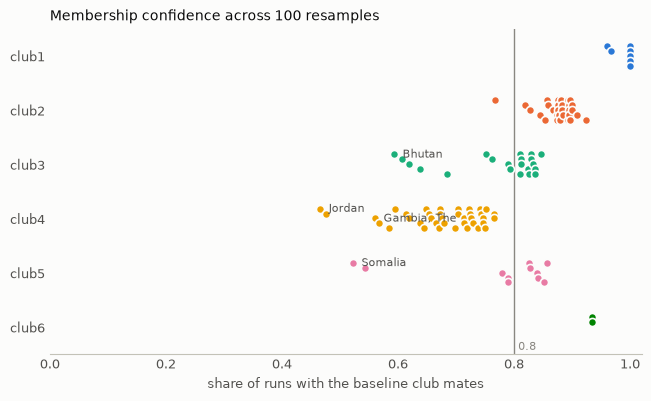

In [10]:
boot.plot_stability();

Club 1 is solid. Some members of the lower clubs move between neighboring clubs, and those memberships deserve less weight in the interpretation.

## 5. β, σ and distribution dynamics

These classical measures use the **unfiltered levels**.
- **β-convergence**: do poorer countries grow faster?
- **σ-convergence**: does the dispersion shrink over time?
- **Distribution dynamics** (Quah): how do countries move between income classes?

In [11]:
absolute = cc.beta_convergence(gdp)
conditional = cc.beta_convergence(gdp, clubs=merged, club_effects=True)
absolute, conditional

(<BetaResult (absolute): beta=-0.0004 (t=-0.24, p=0.813), half-life=1804.8, n=152>,
 <BetaResult (conditional): beta=-0.0151 (t=-14.78, p=9.83e-31), half-life=33.1, n=152>)

In [12]:
sigma = cc.sigma_convergence(gdp, clubs=merged)
sigma.trend()[["n_units", "change", "slope", "t_value", "converging"]]

,n_units,change,slope,t_value,converging
group,,,,,
all units,152,0.159,0.005,11.283,False
club1,50,-0.467,-0.015,-38.971,True
club2,30,-0.366,-0.012,-12.811,True
club3,21,-0.389,-0.010,-20.635,True
club4,38,-0.221,-0.004,-3.633,True
club5,11,-0.125,-0.005,-3.554,True


In [13]:
dynamics = cc.distribution_dynamics(gdp, lag=5, clubs=merged)
dynamics.distributions()

,initial,final,ergodic
class,,,
< 0.16,0.099,0.263,0.277
0.16–0.40,0.322,0.138,0.106
0.40–0.74,0.217,0.178,0.118
0.74–1.92,0.184,0.204,0.181
≥ 1.92,0.178,0.217,0.318


Together these tell a consistent story:
- no absolute β-convergence, and dispersion rises across all countries;
- yet strong convergence *within* the clubs;
- and a long-run distribution that piles up at both ends ("twin peaks").

## 6. Replicating a Stata analysis

The R package and Stata's `psecta` differ in a few rules: the core group, how c* is raised, the default trimming and rounding. `convention="Stata"` follows `psecta`. With it, the labor-productivity clubs of Mendez (2020) are reproduced exactly from the raw data:

In [14]:
lp = cc.load_productivity("lp", sample="other")  # 82 countries, 1990-2014
stata = cc.find_clubs(cc.hp_filter(np.log(lp)), convention="Stata", time_trim=0.333)
[len(c) for c in stata], [len(c) for c in stata.merge("PS")]

([31, 20, 8, 15, 5, 2], [51, 8, 15, 5, 2])

## 7. Export a report

`report` runs everything above and writes a single self-contained HTML file, which can serve as a replication appendix:

In [15]:
path = cc.report(gdp, bootstrap=50, title="Convergence clubs in GDP per capita").save("report.html")
path

PosixPath('report.html')

## Next steps

- [Feature tour](feature-tour.ipynb): every other feature, each with its output — R and Stata conventions, renaming clubs, themes and plot styles, the bootstrap variants, Pesaran's pairwise test, determinants of club membership, interactive charts, maps and the command line.
- [Guides](guide/): every option, how to choose the settings, how the results are validated against R and Stata, and the references.
- From the command line: `convergence-clubs data.csv --log --hp-filter --merge PS --report report.html`.